| Method | On-Policy | Off-Policy |
|---|---|---|
| **Value-Based** | SARSA | Q-Learning, DQN |
| **Actor-Critic** | A2C, PPO | TD3, SAC |
| **Pure Policy Gradient** | REINFORCE | Off-Policy REINFORCE (with Importance Sampling Correction) |

## Why Do We Want Multiple Gradient Updates on the Same Batch of Data?

Suppose REINFORCE collects **1,000 transitions**, performs only **one gradient update**, and then discards the data.

Why would we want to perform multiple gradient updates on the same batch of data? And why does doing so introduce new problems?

### REINFORCE: The Original Approach

1. Collect data using the current policy.
2. Perform one gradient update.
3. Collect new data using the updated policy.
4. Perform another gradient update.
5. Repeat.

This is inefficient because **environment interaction is expensive!**

Instead, we would prefer to:

1. Collect a large batch of data using the current policy.
2. Perform multiple gradient updates using the same batch.
3. Collect new data only after several updates.

### The Fundamental Trade-off

There are two competing objectives:

1. **Sample Efficiency:** Interacting with the environment is expensive, so we want to reuse the same batch of data for multiple training updates.

2. **Gradient Correctness:** After each policy update, the previously collected data no longer comes from the current policy. If we directly reuse that data to compute the REINFORCE gradient, the resulting gradient estimate may become **biased**.

**The core challenge:** How can we reuse collected experience to improve sample efficiency without introducing excessive bias into our policy gradient estimates?

In [1]:
import numpy as np

rng = np.random.default_rng(42)

old = np.array([0.8, 0.2])
new = np.array([0.5, 0.5])
rewards = np.array([0.0, 10.0])

actions = rng.choice(2, size=10_000, p=old)

ratio = new[actions] / old[actions]

print("Old batch average:", rewards[actions].mean())
print("IS estimate:", np.mean(ratio * rewards[actions]))
print("True new expectation:", new @ rewards)

Old batch average: 1.954
IS estimate: 4.885
True new expectation: 5.0


### Importance Sampling (IS)

Here comes the magic:

**We haven't sampled a single action from the New Policy, yet using only data collected by the Old Policy, we can estimate the New Policy's Expected Reward with high accuracy!**

This is **Importance Sampling (IS)**.

Imagine the Old Policy collected 1,000 actions.

If we directly use the Old Policy's data, A would be overrepresented, while B would be underrepresented.

To correct this, we assign a **weight** to each sample:

$$
w(a)=\frac{\pi_{\text{new}}(a)}{\pi_{\text{old}}(a)}
$$

For A:

$$
w(A)=\frac{0.5}{0.8}=0.625
$$

For B:

$$
w(B)=\frac{0.5}{0.2}=2.5
$$

Therefore:

- The Old Batch contains approximately 800 samples of A. Multiplying each by 0.625 gives an effective weight equivalent to 500 samples of A.
- The Old Batch contains approximately 200 samples of B. Multiplying each by 2.5 gives an effective weight equivalent to 500 samples of B.

**We haven't collected any new samples. Instead, through reweighting, we've made the old samples represent the new probability distribution in expectation.**

This is the intuition behind Importance Sampling.

During a single batch of training:

- **Old Policy** remains fixed.
- **Rewards and Advantage Estimates** remain fixed.
- **New Policy** parameters are continuously updated through gradient updates.
- **Importance Ratios** change as the New Policy changes.
- **Clipping** limits the incentive to keep pushing action probabilities too far in the same direction.

---

Suppose an action has an **Advantage of +5**. The Old Policy assigned action A a probability of 50%, but the New Policy has already increased that probability to 70%.

Since A is a good action, **why does PPO prefer to stop extracting additional optimization gains from this old sample, rather than continuing to encourage the policy to push A's probability toward 90%?**

---

### Derive PPO surrogate objective

Our original objective is:

$$
L = R\log(p)
$$

Taking the derivative with respect to $p$:

$$
\frac{dL}{dp} = \frac{R}{p}
$$

For example, if $R=1$ and $p=0.2$, the gradient is:

$$
\frac{1}{0.2}=5
$$

Now, suppose we want to reuse data collected by the old policy.

To account for the difference between the old and new policies, we multiply the gradient by the **importance sampling (IS) ratio**:

$$
\text{gradient} = \frac{R}{p}\cdot\frac{p}{p_{\text{old}}}
$$

Notice something interesting here:

**The $p$ in the numerator and denominator cancel out!**

So we're left with:

$$
\text{gradient}=\frac{R}{p_{\text{old}}}
$$

Now we need to find a new objective function whose derivative with respect to $p$ gives us exactly this gradient.

That's actually quite simple:

$$
\boxed{
L_{\text{new}}=R\frac{p}{p_{\text{old}}}
}
$$

Since $R$ and $p_{\text{old}}$ are treated as constants, taking the derivative gives us:

$$
\frac{dL_{\text{new}}}{dp}=\frac{R}{p_{\text{old}}}
$$

**That's exactly the gradient we wanted!**

### Key Takeaway

We apply importance sampling **to the gradient**, not to the original `logprob × reward` objective!

---
### Why storing log prob instead of probability?

when P is too small, hard to store, logprob is a lot easier. Also, gradient needs logprob anyway!

### Why need a surrogate object? instead of importance sampling ratio * old gradient?

So Pytorch can auto do backprop for us! Pytorch can calculate the derative of it.

Remember:
>gradient is the tool we used to change the model.
>
>Loss/objective is the tool we use to produce gradient.

---

## Why Doesn't PPO Use Simple Ratio Clipping?

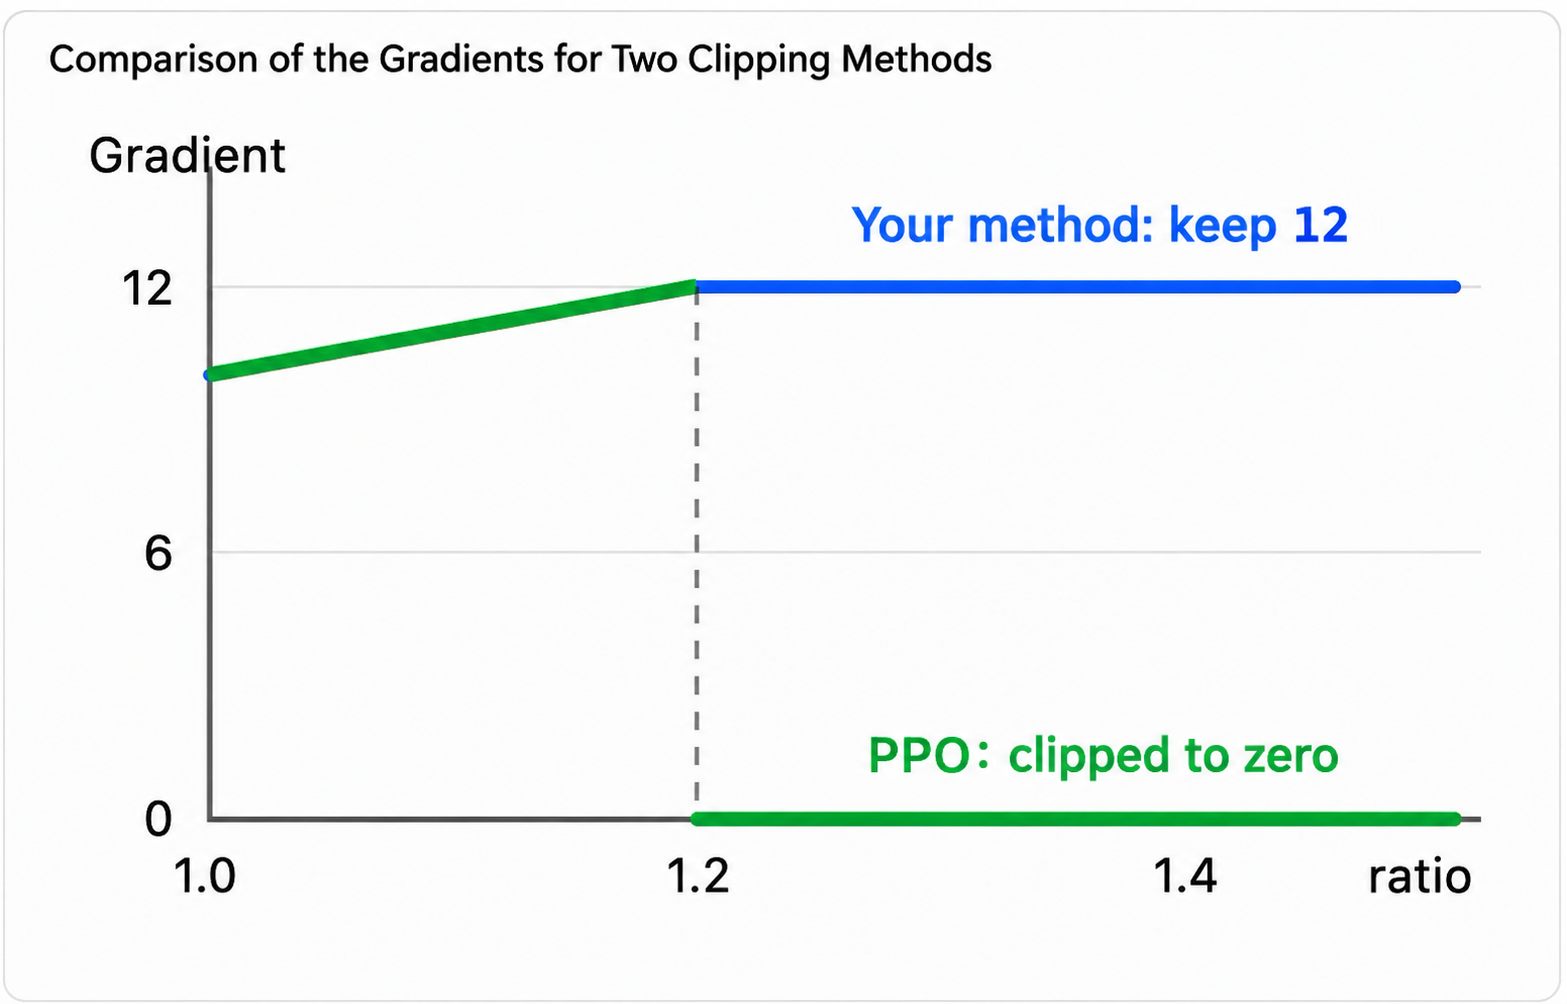

Because the two approaches solve different problems.

### Approach 1: Clip the IS Ratio Used to Scale the Gradient

**Goal:** Prevent the importance sampling (IS) ratio from excessively amplifying the gradient.

For example, if the IS ratio is 100, the importance-weighted gradient could be amplified by a factor of 100. By clipping the ratio to 1.2, we limit that amplification to at most 1.2.

The gradient can still drive policy updates, even after the ratio exceeds the clipping threshold.

### Approach 2: PPO's Clipped Objective

**Goal:** Prevent the same sample from continuously pushing the policy too far in the same direction.

For example, suppose the probability of a good action has already increased by 50% relative to the old policy.

PPO considers this sample to have contributed enough to the update. It stops rewarding further increases in that action's probability.

Even if the gradient is small, repeated updates can gradually push the new policy further and further away from the old policy.

Therefore, **PPO clipping is designed to stop a sample from contributing further gradient in an already over-updated direction, rather than merely limiting the magnitude of its gradient.**

### Key Takeaway

- **Simple ratio clipping:** Limits how strongly a sample can push the policy.
- **PPO clipping:** Stops a sample from **pushing the policy further** once it has moved sufficiently far in a beneficial direction.


---

## Why Isn't PPO Clipping Enough?

**PPO clipping limits how much an individual sample can contribute to a policy update, but it does not guarantee that the overall policy stays close to the old policy.**

The key reason is that **neural network parameters are shared across samples**.

Consider two samples:

- **Sample A:** IS ratio = 1.3, advantage is positive. It has already crossed the clipping threshold (1.2), so its gradient contribution becomes 0.
- **Sample B:** IS ratio = 1.1, advantage is positive. It is not clipped, so it still contributes to the gradient.

When Sample B updates the neural network parameters, those same parameters also affect Sample A's probability.

As a result, Sample A's ratio might increase from 1.3 to 1.5, even though Sample A itself contributes no gradient.

**Key takeaway:** Clipping controls an individual sample's incentive to push the policy further, not the actual change in the entire policy.

## What Problem Does KL Divergence Solve?

The IS ratio measures how the probability of **one sampled action** changes between the old and new policies.

But a policy is a complete probability distribution over all possible actions.

For example:

| Action | Old Policy | New Policy |
|---|---|---|
| A | 50% | 80% |
| B | 30% | 10% |
| C | 20% | 10% |

The new policy is clearly different from the old one.

**KL divergence measures how different two probability distributions are.**

$$
D_{KL}(\pi_{\text{old}}\|\pi_{\text{new}})
=\sum_a\pi_{\text{old}}(a|s)\log\frac{\pi_{\text{old}}(a|s)}{\pi_{\text{new}}(a|s)}
$$

Intuitively:

- **KL = 0:** The two distributions are identical.
- **Larger KL:** The distributions are generally more different.

Unlike a conventional distance, KL divergence is not symmetric.

**Key takeaway:** The IS ratio tells us how one action's probability changed. KL divergence tells us how much the entire policy distribution changed.

## How Does PPO Use KL Divergence?

One common approach is **KL early stopping**.

Suppose we set:

`target_kl = 0.01`

PPO reuses the same batch of samples for multiple training epochs.

After each epoch (or optimization step), we estimate the KL divergence between the current policy and the old policy.

For example:

| Epoch | Approx. KL | Decision |
|---|---|---|
| 1 | 0.003 | Continue |
| 2 | 0.007 | Continue |
| 3 | 0.012 | Stop |
| 4 | — | Not executed |

*Illustrative example, assuming an early-stopping threshold of 0.01.*

Once the estimated KL exceeds the threshold, we stop further updates on the current batch.

This gives PPO two complementary mechanisms:

- **Clipping:** Prevents individual samples from continuously pushing the policy too far in an already beneficial direction.
- **KL early stopping:** Monitors how far the overall policy has moved from the old policy and stops training when that change becomes too large.

KL early stopping is optional in PPO implementations, and an estimated KL threshold is not a strict mathematical guarantee.

### Final Mental Model

**Clipping controls individual samples' contributions to the gradient. KL divergence monitors the overall change in the policy.**

Even when a sample's gradient contribution becomes zero, other samples can still change its probability through shared neural network parameters.

That is why clipping alone cannot guarantee that the new policy remains close to the old policy.